In a reactor with excess A the reaction A+B=C reaches equilibrium .Initial concentration are [a]0 =2 [b]=1 and [c]=0mol/l if x mol/l of C is formed Kc=x/(2-x)(1-x) which rearranges to the quadratic equation Kc.x^2 -(3Kc+1).x +2Kc=0 write a python programme that ; (a) reads Kc using input()prints the data type of the raw input and of the converted value and shows a clear message (no crash)if the text is not a number or if Kc<or=0;

In [5]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input:", raw_kc)
print("Raw input data type:", type(raw_kc).__name__)

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: Kc must be a number greater than zero.")
else:
    print("Converted value:", kc)
    print("Converted value data type:", type(kc).__name__)

    if not math.isfinite(kc) or kc <= 0:
        print("Invalid Kc: enter a finite number greater than zero.")
    else:
        print("Kc is valid.")

Raw input: 0.5
Raw input data type: str
Converted value: 0.5
Converted value data type: float
Kc is valid.


(b)find a,b,c the bdiscriminate both roots;    (c) select the physically meaningful root 90<=x<=1,because B is limiting);     (d) prints equilibrium [A] ,[B],[C] 3 decimals and the conversion of the limiting reactant B =x/[B]o * 100%    (e)classifies the conversion using if/elif/else:>=70%"High'' , .=40%"Moderate'' ,otherwise ''low''.   Test with Kc =4 ,Kc=0.5 Kc=abc and Kc=-2

In [6]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input:", raw_kc)
print("Raw input data type:", type(raw_kc).__name__)

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: Kc must be a number greater than zero.")
else:
    print("Converted value:", kc)
    print("Converted value data type:", type(kc).__name__)

    if not math.isfinite(kc) or kc <= 0:
        print("Invalid Kc: enter a finite number greater than zero.")
    else:
        # Kc*x^2 - (3*Kc + 1)*x + 2*Kc = 0
        a = kc
        b = -(3 * kc + 1)
        c = 2 * kc

        discriminant = b**2 - 4 * a * c
        print(f"Coefficients: a={a}, b={b}, c={c}")
        print(f"Discriminant: {discriminant:.3f}")

        if discriminant < 0:
            print("No real roots.")
        else:
            root1 = (-b + math.sqrt(discriminant)) / (2 * a)
            root2 = (-b - math.sqrt(discriminant)) / (2 * a)
            print(f"Roots: {root1:.6f}, {root2:.6f}")

            physical_roots = [
                root for root in (root1, root2)
                if 0 <= root <= 1
            ]

            if not physical_roots:
                print("No physically meaningful root in the range 0 <= x <= 1.")
            else:
                x = physical_roots[0]
                initial_a = 2
                initial_b = 1

                equilibrium_a = initial_a - x
                equilibrium_b = initial_b - x
                equilibrium_c = x
                conversion = x / initial_b * 100

                print(f"Equilibrium [A]: {equilibrium_a:.3f} mol/L")
                print(f"Equilibrium [B]: {equilibrium_b:.3f} mol/L")
                print(f"Equilibrium [C]: {equilibrium_c:.3f} mol/L")
                print(f"B conversion: {conversion:.3f}%")

                if conversion >= 70:
                    print("Conversion classification: High")
                elif conversion >= 40:
                    print("Conversion classification: Moderate")
                else:
                    print("Conversion classification: Low")

Raw input: 0.5
Raw input data type: str
Converted value: 0.5
Converted value data type: float
Coefficients: a=0.5, b=-2.5, c=1.0
Discriminant: 4.250
Roots: 4.561553, 0.438447
Equilibrium [A]: 1.562 mol/L
Equilibrium [B]: 0.562 mol/L
Equilibrium [C]: 0.438 mol/L
B conversion: 43.845%
Conversion classification: Moderate


2 Batch reactor simulation and batch tracking 
PartA Hydrogen peroxide decomposes in a batch reactor by a first order reaction dC/dT =-KC.Use the euler method C_new=C_old deltat take Co =1.5mol/l,k=0.05 min^-1 de4ltat =2 min
(i)using a for loop simulate 20 min and print a table of time (min),concentration (mol/l) and conversion % 
(ii)using math .exp() calculate the exact value Coe^(-kt) at 20 min and print the absolute error of thr euler result 
(iii)using a while loop repeat the simulation umtil conversion reaches 50% or time reaches 100min print the needed and final concentration

In [4]:
import math

initial_concentration = 1.5  # mol/L
k = 0.05                     # min^-1
delta_t = 2                  # min
simulation_time = 20         # min

# Euler simulation for 20 minutes
concentration = initial_concentration
steps = simulation_time // delta_t

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
for step in range(steps + 1):
    time = step * delta_t
    conversion = (
        (initial_concentration - concentration)
        / initial_concentration
        * 100
    )
    print(f"{time:>8}\t{concentration:>21.4f}\t{conversion:>14.2f}")

    if step < steps:
        concentration = concentration - k * concentration * delta_t

# Exact concentration and absolute error at 20 minutes
exact_concentration = initial_concentration * math.exp(-k * simulation_time)
absolute_error = abs(exact_concentration - concentration)

print(f"\nExact concentration at {simulation_time} min: "
      f"{exact_concentration:.4f} mol/L")
print(f"Absolute error at {simulation_time} min: "
      f"{absolute_error:.4f} mol/L")

# Euler simulation until conversion reaches 50% or time reaches 100 minutes
concentration = initial_concentration
time = 0
conversion = 0

while conversion < 50 and time < 100:
    concentration = concentration - k * concentration * delta_t
    time += delta_t
    conversion = (
        (initial_concentration - concentration)
        / initial_concentration
        * 100
    )

print(f"\nTime needed to reach at least 50% conversion: {time} min")
print(f"Final concentration: {concentration:.4f} mol/L")
print(f"Final conversion: {conversion:.2f}%")

Time (min)	Concentration (mol/L)	Conversion (%)
       0	               1.5000	          0.00
       2	               1.3500	         10.00
       4	               1.2150	         19.00
       6	               1.0935	         27.10
       8	               0.9842	         34.39
      10	               0.8857	         40.95
      12	               0.7972	         46.86
      14	               0.7174	         52.17
      16	               0.6457	         56.95
      18	               0.5811	         61.26
      20	               0.5230	         65.13

Exact concentration at 20 min: 0.5518 mol/L
Absolute error at 20 min: 0.0288 mol/L

Time needed to reach at least 50% conversion: 14 min
Final concentration: 0.7174 mol/L
Final conversion: 52.17%


part B Reactor tags such as REACTOR-07/B-2026 are stored as text.write a program that reads a tag ,loops through each character ,and prints the number of digits and the sum of the digits .show a message for an empty tag and for a tag with no digits.Test with REACTOR-07/B-2026 ,an empty tag and ABCDEF

In [7]:
tag = input("Enter reactor tag: ")

if not tag.strip():
    print("The tag is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in tag:
        if "0" <= character <= "9":
            digit_count += 1
            digit_sum += int(character)

    print("Number of digits:", digit_count)
    print("Sum of digits:", digit_sum)

    if digit_count == 0:
        print("The tag contains no digits.")

Number of digits: 6
Sum of digits: 17


3 CATALYST-PAIR SCREENING AND SAMPLING SCHEDULE 
Part A.A laboratory has n candidate catalysts and wants to test the r best of them together where order does not matter Write a recursive function factorial (n) (remember the base for 0) and aa function combination (n,r) =n!/(r!(n-r)) that uses it Reject invalid input (negative values ,r>n) print the no of possible catalysts sets for n=7,n=2,and show the message for n=4,n=6

In [9]:
def factorial(n):
    if n < 0:
        raise ValueError("Factorial is not defined for negative numbers.")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0:
        raise ValueError("n and r must be non-negative.")
    if r > n:
        raise ValueError("r cannot be greater than n.")

    return factorial(n) // (factorial(r) * factorial(n - r))


test_cases = [(7, 2), (4, 6)]

for n, r in test_cases:
    try:
        print(f"Number of catalyst sets for n={n}, r={r}: {combination(n, r)}")
    except ValueError as error:
        print(f"Invalid input for n={n}, r={r}: {error}")

Number of catalyst sets for n=7, r=2: 21
Invalid input for n=4, r=6: r cannot be greater than n.


Part B During a distillation run samples are taken at times =fIBONACCI NUMBER * 5 min.Write an interative function fib_iter(n) that returns list of the first n fibonnacci numbers,and a recursive function fib_rec(k) that returns the k-th fibonnacci number(Fo=0,F1=1) for n=9,check that both functions agree and print a table :Sample No.|Fibonnacci tag |Sampling time(min)

In [10]:
def fib_iter(n):
    if n < 0:
        raise ValueError("n must be non-negative.")

    numbers = []
    first, second = 0, 1

    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second

    return numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k must be non-negative.")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 9
fib_numbers = fib_iter(n)
recursive_numbers = [fib_rec(k) for k in range(n)]

if fib_numbers == recursive_numbers:
    print("Both functions agree.")
else:
    print("The functions do not agree.")

print(f"{'Sample No.':<12}{'Fibonacci tag':<16}{'Sampling time (min)'}")
for sample_no, fib_number in enumerate(fib_numbers, start=1):
    sampling_time = fib_number * 5
    print(f"{sample_no:<12}{fib_number:<16}{sampling_time}")

Both functions agree.
Sample No.  Fibonacci tag   Sampling time (min)
1           0               0
2           1               5
3           1               5
4           2               10
5           3               15
6           5               25
7           8               40
8           13              65
9           21              105


KINETICS AND GAS DATA :PANDAS AND MATPLOTLIB
Decomposition of hydrogen peroxide was studied with two catalyst loading the concentration (mol/l)was recorded
TIME(min)    Run_mil_l(low reading)    Run2_mol_l(high loading)
  0              1.20                    1.20
  10             0.98                    0.80
  20             0.80                    0.54
  30             0.66                    0.36
  40             0.54                    0.24
  50             0.44                    0.16
(a)Create a data frame from this table save it as kinetics.csv(without the index column) and as kinetics.json.Read the CSV back and print its shape and data types.
(b) Print the mean and standard deviation of Run 1 and Run 2 ,and stste which run shows more variation.
(c) Plot both rums on a graph (time on x-axis) with title,axis labels with units legend and grid.
(d) Carbon dioxide is compressed slowly in a piston _cylinder at constant temperature:
VOLUME L       1       2      3      4       5
Pressure_bar   3.02    1.49   1.01   0.76    0.59 
plot pressure vs volume as a scatter plot calculate k as the mean of P * V and draw the reference curve P=k/v on the same graph add labels with units and legendK

CSV shape: (6, 3)
CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object
Run1_mol_L: mean = 0.770 mol/L, standard deviation = 0.284 mol/L
Run2_mol_L: mean = 0.550 mol/L, standard deviation = 0.392 mol/L
Run 2 shows more variation.


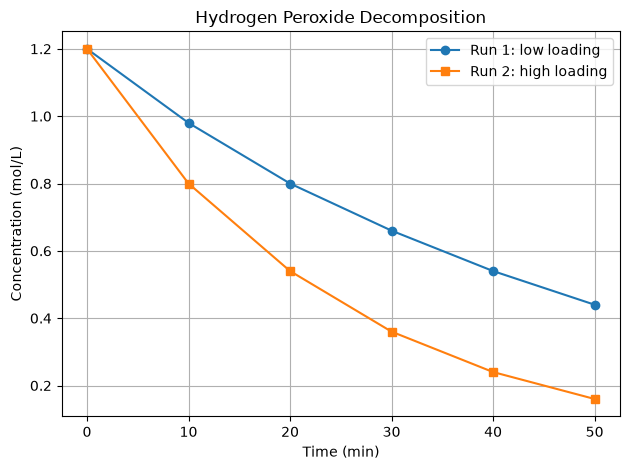


Mean value of P * V, k = 3.004 bar·L


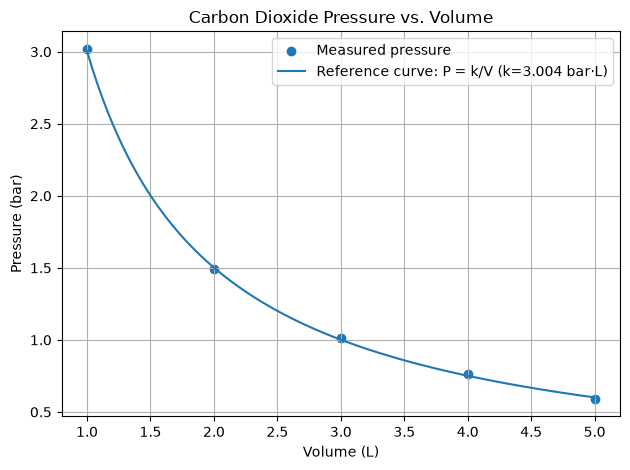

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hydrogen peroxide concentration data
data = {
    "Time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.20, 0.98, 0.80, 0.66, 0.54, 0.44],
    "Run2_mol_L": [1.20, 0.80, 0.54, 0.36, 0.24, 0.16],
}

kinetics = pd.DataFrame(data)

# Save the data and read the CSV back
kinetics.to_csv("kinetics.csv", index=False)
kinetics.to_json("kinetics.json", orient="records", indent=2)

read_back = pd.read_csv("kinetics.csv")
print("CSV shape:", read_back.shape)
print("CSV data types:")
print(read_back.dtypes)

# Print mean and sample standard deviation
for column in ["Run1_mol_L", "Run2_mol_L"]:
    print(
        f"{column}: mean = {read_back[column].mean():.3f} mol/L, "
        f"standard deviation = {read_back[column].std():.3f} mol/L"
    )

if read_back["Run1_mol_L"].std() > read_back["Run2_mol_L"].std():
    print("Run 1 shows more variation.")
else:
    print("Run 2 shows more variation.")

# Plot hydrogen peroxide concentration for both runs
plt.figure()
plt.plot(read_back["Time_min"], read_back["Run1_mol_L"], marker="o", label="Run 1: low loading")
plt.plot(read_back["Time_min"], read_back["Run2_mol_L"], marker="s", label="Run 2: high loading")
plt.title("Hydrogen Peroxide Decomposition")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Carbon dioxide pressure-volume data
volume_l = np.array([1, 2, 3, 4, 5], dtype=float)
pressure_bar = np.array([3.02, 1.49, 1.01, 0.76, 0.59])

k = np.mean(pressure_bar * volume_l)
print(f"\nMean value of P * V, k = {k:.3f} bar·L")

# Plot measured pressures and the reference curve P = k / V
volume_curve = np.linspace(volume_l.min(), volume_l.max(), 200)
pressure_curve = k / volume_curve

plt.figure()
plt.scatter(volume_l, pressure_bar, label="Measured pressure")
plt.plot(volume_curve, pressure_curve, label=f"Reference curve: P = k/V (k={k:.3f} bar·L)")
plt.title("Carbon Dioxide Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()